# PCA: renovar candidatos dentro de la poda de k

Diez semillas, 100 pasos uniformes y 10000 de continuación. PCA centrada + media al 95 %, QR directo, 128 activos, pérdida histórica datos+PDE+IC, veinte snapshots cada cinco pasos del último intervalo de cien. Se conserva la regla de poda por log2(|r anterior|/|r actual|), piso 1e-12 y cancelación si uno de los k grados elegidos es negativo.

El brazo nuevo renueva 4096 candidatos Sobol antes de recoger cada intervalo de snapshots. El conjunto permanece fijo durante los veinte momentos, por lo que cada fila mantiene sus coordenadas. La primera selección y primer intervalo comparten pesos, Adam y puntos con los tres controles. La primera actualización diferenciada ocurre en paso 200. QR se restringe a candidatos que no están activos; el rango se obtiene de la historia completa y determina k. Tras insertar puntos se realinea el residuo basal en las nuevas coordenadas.

Los controles de poda fija, reconstrucción fija y reconstrucción con candidatos renovados se reutilizan de los notebooks 21 y 19; manifest.json identifica sus rutas. Comparar las dos podas aísla la renovación y sus consecuencias sobre el rango. k puede diferir entre trayectorias; no se impone un calendario compartido en esta prueba. Se conserva también la reconstrucción renovada para comparar actualización bajo la misma política de candidatos.

| Método | RMSE prueba ± DE | Residuo RMS | RMSE IC |
|---|---:|---:|---:|
| Poda: candidatos renovados | 0.11016 ± 0.02592 | 0.09063 | 0.12825 |
| Poda: candidatos fijos | 0.09870 ± 0.02202 | 0.08080 | 0.12944 |
| Reconstrucción: candidatos fijos | 0.07144 ± 0.00977 | 0.16801 | 0.08991 |
| Reconstrucción: candidatos renovados | 0.07096 ± 0.01749 | 0.16187 | 0.08390 |


Poda: candidatos renovados frente a Poda: candidatos fijos: diferencia media RMSE +0.01147; mejora en 2/10 semillas.

Poda: candidatos renovados frente a Reconstrucción: candidatos fijos: diferencia media RMSE +0.03872; mejora en 0/10 semillas.

Poda: candidatos renovados frente a Reconstrucción: candidatos renovados: diferencia media RMSE +0.03920; mejora en 1/10 semillas.

**Comparación**

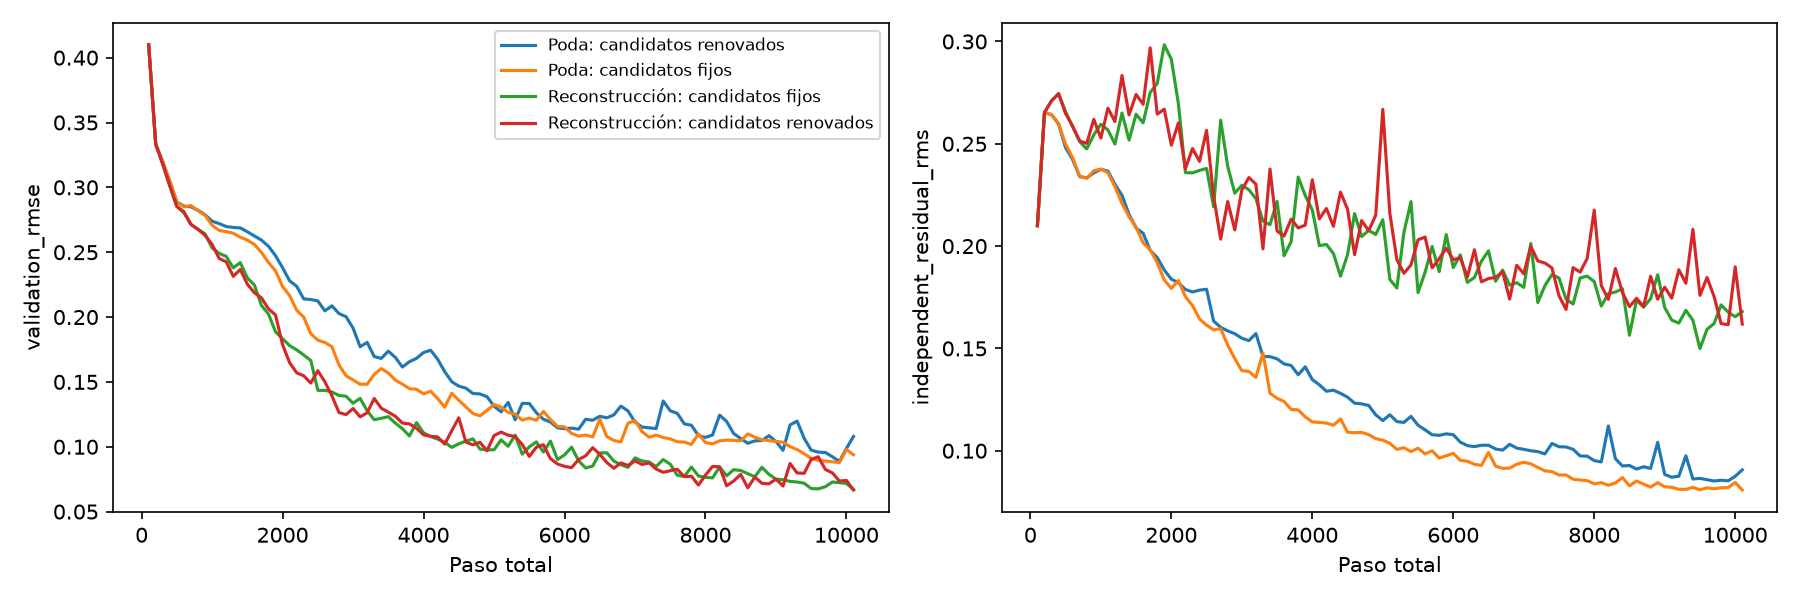

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/refresh_pruning/pca95_refresh_pruning_10_seeds_10k_v1/comparison.png'), format='png', embed=True))


Poda: candidatos renovados: 990/990 podas aceptadas; k entre 2 y 9, media 5.82.

Poda: candidatos fijos: 990/990 podas aceptadas; k entre 2 y 10, media 6.01.

Se evalúa el modelo terminal en prueba reservada; ninguna configuración se elige usando prueba. La desviación es dispersión entre semillas. Los tiempos incluyen compilación y observación y no prueban aceleración. Las auditorías verifican la poda, las propuestas QR elegibles, los conjuntos renovados, el inicio común y tamaño constante. Permanencias y censura final están en residence.csv de cada corrida nueva.

Reproducir: `python scripts/run_collocation_refresh_pruning.py`. Se reutilizan las corridas completas. Las figuras están incrustadas como PNG. Si este control no mejora el error de solución, conviene estudiar el balance de pérdidas antes de seguir modificando el selector.